In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report 

In [2]:
df = pd.read_csv("svm_student_performance.csv")

In [3]:
df.head()

,Study_Hours,Attendance_Percent,Previous_Score,Result
0,4.37,84.91,47.03,0
1,9.56,76.80,70.22,1
2,7.59,65.48,91.74,1
3,6.39,90.69,82.59,1
4,2.40,84.24,87.43,0


In [4]:
df.shape

(500, 4)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Study_Hours         500 non-null    float64
 1   Attendance_Percent  500 non-null    float64
 2   Previous_Score      500 non-null    float64
 3   Result              500 non-null    int64  
dtypes: float64(3), int64(1)
memory usage: 15.8 KB


In [6]:
df.describe()

,Study_Hours,Attendance_Percent,Previous_Score,Result
count,500.000000,500.000000,500.000000,500.000000
mean,5.487080,74.097340,68.641360,0.590000
std,2.688059,14.274752,19.317658,0.492326
min,1.050000,50.230000,35.320000,0.000000
25%,3.175000,61.452500,50.677500,0.000000
50%,5.620000,73.590000,70.085000,1.000000
75%,7.805000,86.320000,85.527500,1.000000
max,9.940000,99.990000,99.960000,1.000000


In [7]:
df.isnull().sum()

Study_Hours           0
Attendance_Percent    0
Previous_Score        0
Result                0
dtype: int64

In [8]:
df["Result"].value_counts()

Result
1    295
0    205
Name: count, dtype: int64

In [9]:
df["Result"].value_counts(normalize=True)

Result
1    0.59
0    0.41
Name: proportion, dtype: float64

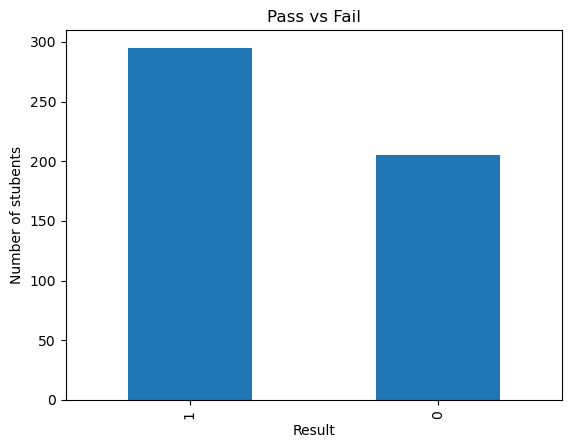

In [10]:
import matplotlib.pyplot as plt
df["Result"].value_counts().plot(kind="bar")
plt.xlabel("Result")
plt.ylabel("Number of stubents")
plt.title("Pass vs Fail")
plt.show()

In [11]:
X = df[["Study_Hours", "Attendance_Percent","Previous_Score"]]
y = df["Result"]

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,random_state=42, stratify=y
)

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_Scaled = scaler.transform(X_test)

In [14]:
model = SVC(kernel = "linear", C=1)

In [15]:
model.fit(X_train_scaled, y_train)

,C,1
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [16]:
y_pred = model.predict(X_test_Scaled)

In [17]:
print(y_pred[:10])

[1 1 1 0 0 1 0 1 1 1]


In [18]:
comparison = pd.DataFrame({
    "Actual":y_test.values, "Prediction":y_pred
})
comparison.head(10)

,Actual,Prediction
0,1,1
1,1,1
2,1,1
3,0,0
4,0,0
5,1,1
6,0,0
7,1,1
8,1,1
9,1,1


In [19]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:",accuracy)

Accuracy: 1.0


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression())
])

pipeline.fit(X_train, y_train)

train_pred = pipeline.predict(X_train)
test_pred = pipeline.predict(X_test)

train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 0.9875
Testing Accuracy: 1.0
